# 05 — Chọn mô hình nền cho stacking

Tinh chỉnh 6 mô hình trên MNIST, so sánh 15 cặp và 20 bộ ba bằng soft voting, rồi đề xuất nhóm cho stacking AdaBoost ở notebook 06. Không dùng test để chọn mô hình.


## 1. Import và cấu hình

Nạp thư viện, đặt seed và tạo thư mục lưu kết quả `results/select_base_models/`.


In [1]:
import hashlib, json, sys, time, warnings
from itertools import combinations
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from IPython.display import display
from joblib import dump
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
OUTPUT = ROOT / 'results' / 'select_base_models'
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED = 42

## 2. Chia dữ liệu

Đọc dữ liệu từ loader trả về 4 giá trị; chỉ sử dụng phần train. Với 60.000 ảnh train, chia stratify thành 50.000 train và 10.000 validation; trong train chia tiếp 40.000 fit và 10.000 tuning. Dùng seed 42 cho cả hai lần chia.


In [2]:
X, y, _, _ = load_prepared_mnist()   # X_train, y_train, X_test, y_test; test không dùng ở notebook này
X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=int)
tr, va = train_test_split(np.arange(len(y)), test_size=10000, stratify=y, random_state=SEED)
X_train, y_train, X_val, y_val = X[tr], y[tr], X[va], y[va]
X_fit, X_tune, y_fit, y_tune = train_test_split(X_train, y_train, test_size=10000, stratify=y_train, random_state=SEED)
print('Refit train:', X_train.shape, 'Validation:', X_val.shape)
print('Fit tuning:', X_fit.shape, 'Holdout tuning:', X_tune.shape)

Refit train: (50000, 784) Validation: (10000, 784)
Fit tuning: (40000, 784) Holdout tuning: (10000, 784)


## 3. Tuning và refit từng mô hình

Mỗi mô hình thử 3 giá trị của một siêu tham số. Chọn theo accuracy trên tập tuning, F1 macro phá hòa, rồi refit trên 50.000 ảnh train.

SVM chỉ bật tính xác suất khi refit. Trên validation, `accuracy` và phân tích lỗi dùng argmax xác suất; `accuracy_predict` dùng nhãn từ `predict`. Lưu thời gian và cảnh báo; MLP chạy tối đa 60 epoch, chưa bảo đảm hội tụ.


,model,configuration,params
0,SVM,1,"{""C"": 1}"
1,SVM,2,"{""C"": 3}"
2,SVM,3,"{""C"": 10}"
3,Softmax_sklearn,1,"{""C"": 0.01}"
4,Softmax_sklearn,2,"{""C"": 0.1}"
5,Softmax_sklearn,3,"{""C"": 1}"
6,RandomForest,1,"{""min_samples_leaf"": 1}"
7,RandomForest,2,"{""min_samples_leaf"": 2}"
8,RandomForest,3,"{""min_samples_leaf"": 4}"
9,KNN,1,"{""n_neighbors"": 3}"


Tuning: SVM
{'C': 1} F1=0.9744 
{'C': 3} F1=0.9791 
{'C': 10} F1=0.9792 
Cảnh báo: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
SVM hoàn tất; validation accuracy: 0.9833
Tuning: Softmax_sklearn
{'C': 0.01} F1=0.9113 
{'C': 0.1} F1=0.9168 
{'C': 1} F1=0.9164 
Softmax_sklearn hoàn tất; validation accuracy: 0.9214
Tuning: RandomForest
{'min_samples_leaf': 1} F1=0.9646 
{'min_samples_leaf': 2} F1=0.9635 
{'min_samples_leaf': 4} F1=0.9600 
RandomForest hoàn tất; validation accuracy: 0.9669
Tuning: KNN
{'n_neighbors': 3} F1=0.9692 
{'n_neighbors': 5} F1=0.9690 
{'n_neighbors': 7} F1=0.9679 
KNN hoàn tất; validation accuracy: 0.972
Tuning: ExtraTrees
{'min_samples_leaf': 1} F1=0.9675 
{'min_samples_leaf': 2} F1=0.9638 
{'min_samples_leaf': 4} F1=0.9601 
ExtraTrees hoàn tất; validation accuracy: 0.9709
Tuning: MLP256_128
Cảnh báo: Stochastic Optimizer: Maximum iterat

,model,params,f1_macro,accuracy,fit_seconds,warning
0,SVM,{'C': 1},0.9744,0.9746,139.6698,
1,SVM,{'C': 3},0.9791,0.9793,126.6339,
2,SVM,{'C': 10},0.9792,0.9794,130.5283,
3,Softmax_sklearn,{'C': 0.01},0.9113,0.9124,91.2762,
4,Softmax_sklearn,{'C': 0.1},0.9168,0.9180,111.9854,
5,Softmax_sklearn,{'C': 1},0.9164,0.9175,208.3938,
6,RandomForest,{'min_samples_leaf': 1},0.9646,0.9650,9.4787,
7,RandomForest,{'min_samples_leaf': 2},0.9635,0.9639,8.7499,
8,RandomForest,{'min_samples_leaf': 4},0.9600,0.9604,8.3299,
9,KNN,{'n_neighbors': 3},0.9692,0.9694,0.0551,


,model,params,accuracy,accuracy_predict,f1_macro,precision_macro,recall_macro,n_errors,tuning_fit_seconds,fit_seconds,predict_seconds,proba_seconds,warning
0,SVM,{'C': 10},0.9833,0.9826,0.9832,0.9832,0.9832,167,396.8320,965.7658,53.8947,53.3540,The `probability` parameter was deprecated in ...
5,MLP256_128,{'alpha': 0.01},0.9819,0.9819,0.9818,0.9818,0.9819,181,1014.9670,341.4536,0.0473,0.0480,Stochastic Optimizer: Maximum iterations (60) ...
3,KNN,{'n_neighbors': 3},0.9720,0.9720,0.9720,0.9725,0.9716,280,0.1754,0.0309,8.5567,8.4467,
4,ExtraTrees,{'min_samples_leaf': 1},0.9709,0.9709,0.9708,0.9708,0.9708,291,22.2680,10.2358,0.2557,0.2174,
2,RandomForest,{'min_samples_leaf': 1},0.9669,0.9669,0.9668,0.9668,0.9668,331,26.5584,12.4180,0.2645,0.2588,
1,Softmax_sklearn,{'C': 0.1},0.9214,0.9214,0.9205,0.9207,0.9205,786,411.6554,164.6673,0.0127,0.0169,


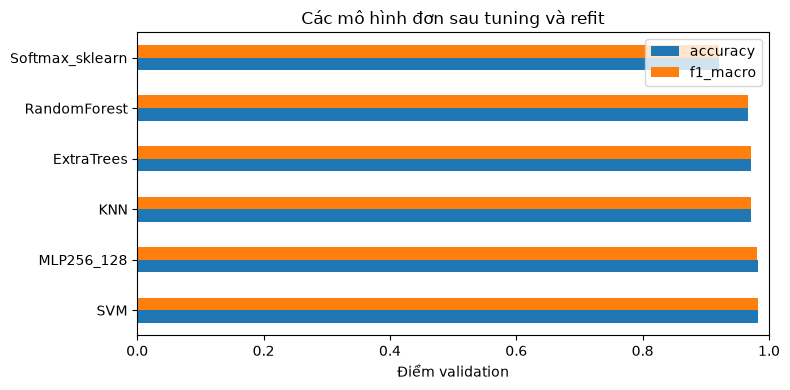

In [3]:
base = {
    'SVM': SVC(kernel='rbf', cache_size=1000, random_state=SEED),
    'Softmax_sklearn': LogisticRegression(solver='lbfgs', max_iter=1000, tol=1e-4),
    'RandomForest': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'KNN': KNeighborsClassifier(weights='distance', n_jobs=-1),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'MLP256_128': MLPClassifier(hidden_layer_sizes=(256, 128), solver='adam', batch_size=256, max_iter=60,
                                early_stopping=False, tol=0, n_iter_no_change=61, random_state=SEED),
}
axes = {'SVM': ('C', (1, 3, 10)), 
        'Softmax_sklearn': ('C', (0.01, 0.1, 1)),
        'RandomForest': ('min_samples_leaf', (1, 2, 4)), 
        'KNN': ('n_neighbors', (3, 5, 7)),
        'ExtraTrees': ('min_samples_leaf', (1, 2, 4)), 
        'MLP256_128': ('alpha', (0.0001, 0.001, 0.01))}

grids = {name: [{p: v} for v in vals] for name, (p, vals) in axes.items()}
display(pd.DataFrame([dict(model=n, configuration=i + 1, params=json.dumps(g))
                      for n, grid in grids.items() for i, g in enumerate(grid)]))

def timed(f, *args):
    t0 = time.perf_counter()
    return f(*args), time.perf_counter() - t0

def fit_timed(model, X, y):
    """Fit, bắt cảnh báo; trả về (thời gian, chuỗi cảnh báo)."""
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(X, y)
    msg = ' | '.join(str(w.message) for w in caught)
    if msg: print('Cảnh báo:', msg, flush=True)
    return time.perf_counter() - t0, msg

models, best_params, tuning_rows, rows, proba, errors = {}, {}, [], [], {}, {}
for name, est in base.items():
    print('Tuning:', name, flush=True)
    scores, tuning_s = [], 0
    for params in grids[name]:
        m = clone(est).set_params(**params)
        sec, msg = fit_timed(m, X_fit, y_fit)
        tuning_s += sec
        yp = m.predict(X_tune)
        acc, f1 = accuracy_score(y_tune, yp), f1_score(y_tune, yp, average='macro')
        scores.append((acc, f1))
        tuning_rows.append(dict(model=name, params=str(params), f1_macro=f1, accuracy=acc,
                                fit_seconds=sec, warning=msg))
        print(params, f'F1={f1:.4f}', 'Có cảnh báo' if msg else '', flush=True)
    best_params[name] = grids[name][scores.index(max(scores))]   

    model = clone(est).set_params(**best_params[name])
    if name == 'SVM': model.set_params(probability=True)
    fit_s, msg = fit_timed(model, X_train, y_train)
    models[name] = model
    assert np.array_equal(model.classes_, np.arange(10))
    label, predict_s = timed(model.predict, X_val)
    proba[name], proba_s = timed(model.predict_proba, X_val)
    pred = proba[name].argmax(1)
    errors[name] = pred != y_val
    p, r, f1, _ = precision_recall_fscore_support(y_val, pred, average='macro', zero_division=0)
    rows.append(dict(model=name, params=str(best_params[name]),
        accuracy=accuracy_score(y_val, pred), accuracy_predict=accuracy_score(y_val, label),
        f1_macro=f1, precision_macro=p, recall_macro=r, n_errors=int(errors[name].sum()),
        tuning_fit_seconds=tuning_s, fit_seconds=fit_s, predict_seconds=predict_s,
        proba_seconds=proba_s, warning=msg))
    print(name, 'hoàn tất; validation accuracy:', rows[-1]['accuracy'], flush=True)

tuning_results = pd.DataFrame(tuning_rows)
singles = pd.DataFrame(rows).sort_values(['accuracy', 'f1_macro', 'model'], ascending=[False, False, True])
display(tuning_results.round(4)); display(singles.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
singles.set_index('model')[['accuracy', 'f1_macro']].plot.barh(ax=ax, xlim=(0, 1))
ax.set(xlabel='Điểm validation', ylabel='', title='Các mô hình đơn sau tuning và refit')
fig.tight_layout(); fig.savefig(OUTPUT / 'single_models.png', dpi=300); plt.show()

## 4. So sánh các cặp và bộ ba

Gộp các mô hình bằng trung bình xác suất với trọng số bằng nhau, rồi đánh giá trên validation.

- `common_errors`: số ảnh mọi thành viên cùng sai.
- `mean_double_fault`: trung bình tỷ lệ cùng sai của các cặp trong nhóm.
- `overlap_ratio`: lỗi chung chia cho số lỗi ít nhất trong nhóm.
- `gain_over_global_best`: chênh accuracy với mô hình đơn tốt nhất, ở dạng tỷ lệ.

Đọc lỗi chung cùng kết quả voting; ít lỗi chung chưa chắc gộp tốt hơn.


In [4]:
RANK_COLUMNS = ['voting_accuracy', 'voting_f1', 'mean_double_fault', 'combo']
rank_combos = lambda t: t.sort_values(RANK_COLUMNS, ascending=[False, False, True, True]).reset_index(drop=True)
vote_of = lambda members: np.mean([proba[n] for n in members], axis=0).argmax(1)   # voting xác suất, trọng số bằng nhau

def compare_combos(size):
    rows = []
    for combo in combinations(models, size):
        errs = [errors[n] for n in combo]
        common, least = np.logical_and.reduce(errs).sum(), min(e.sum() for e in errs)
        vote = vote_of(combo)
        acc = accuracy_score(y_val, vote)
        rows.append(dict(combo=' + '.join(combo), common_errors=int(common),
            mean_double_fault=np.mean([(a & b).mean() for a, b in combinations(errs, 2)]),
            overlap_ratio=common / least if least else np.nan,
            voting_accuracy=acc, voting_f1=f1_score(y_val, vote, average='macro'),
            gain_over_global_best=acc - singles.accuracy.max()))
    return rank_combos(pd.DataFrame(rows))

pairs, triples = compare_combos(2), compare_combos(3)
print(f'{len(pairs)} cặp; hiển thị 10 cặp đầu:'); display(pairs.head(10).round(4))
print(f'{len(triples)} bộ ba; hiển thị 10 bộ ba đầu:'); display(triples.head(10).round(4))

15 cặp; hiển thị 10 cặp đầu:


,combo,common_errors,mean_double_fault,overlap_ratio,voting_accuracy,voting_f1,gain_over_global_best
0,SVM + MLP256_128,117,0.0117,0.7006,0.9838,0.9837,0.0005
1,SVM + ExtraTrees,124,0.0124,0.7425,0.9837,0.9837,0.0004
2,SVM + RandomForest,129,0.0129,0.7725,0.9832,0.9831,-0.0001
3,ExtraTrees + MLP256_128,119,0.0119,0.6575,0.9826,0.9825,-0.0007
4,RandomForest + MLP256_128,129,0.0129,0.7127,0.9825,0.9824,-0.0008
5,KNN + MLP256_128,91,0.0091,0.5028,0.9810,0.9810,-0.0023
6,SVM + KNN,110,0.0110,0.6587,0.9806,0.9806,-0.0027
7,Softmax_sklearn + MLP256_128,140,0.0140,0.7735,0.9798,0.9797,-0.0035
8,SVM + Softmax_sklearn,147,0.0147,0.8802,0.9754,0.9752,-0.0079
9,RandomForest + KNN,160,0.0160,0.5714,0.9745,0.9745,-0.0088


20 bộ ba; hiển thị 10 bộ ba đầu:


,combo,common_errors,mean_double_fault,overlap_ratio,voting_accuracy,voting_f1,gain_over_global_best
0,SVM + KNN + MLP256_128,81,0.0106,0.4850,0.9852,0.9851,0.0019
1,SVM + RandomForest + MLP256_128,97,0.0125,0.5808,0.9840,0.9839,0.0007
2,SVM + ExtraTrees + MLP256_128,92,0.0120,0.5509,0.9839,0.9838,0.0006
3,RandomForest + KNN + MLP256_128,78,0.0127,0.4309,0.9837,0.9836,0.0004
4,RandomForest + ExtraTrees + MLP256_128,117,0.0169,0.6464,0.9835,0.9834,0.0002
5,KNN + ExtraTrees + MLP256_128,75,0.0120,0.4144,0.9832,0.9831,-0.0001
6,SVM + RandomForest + ExtraTrees,121,0.0171,0.7246,0.9827,0.9827,-0.0006
7,SVM + KNN + ExtraTrees,93,0.0128,0.5569,0.9815,0.9815,-0.0018
8,SVM + RandomForest + KNN,94,0.0133,0.5629,0.9813,0.9813,-0.0020
9,SVM + Softmax_sklearn + MLP256_128,103,0.0135,0.6168,0.9810,0.9809,-0.0023


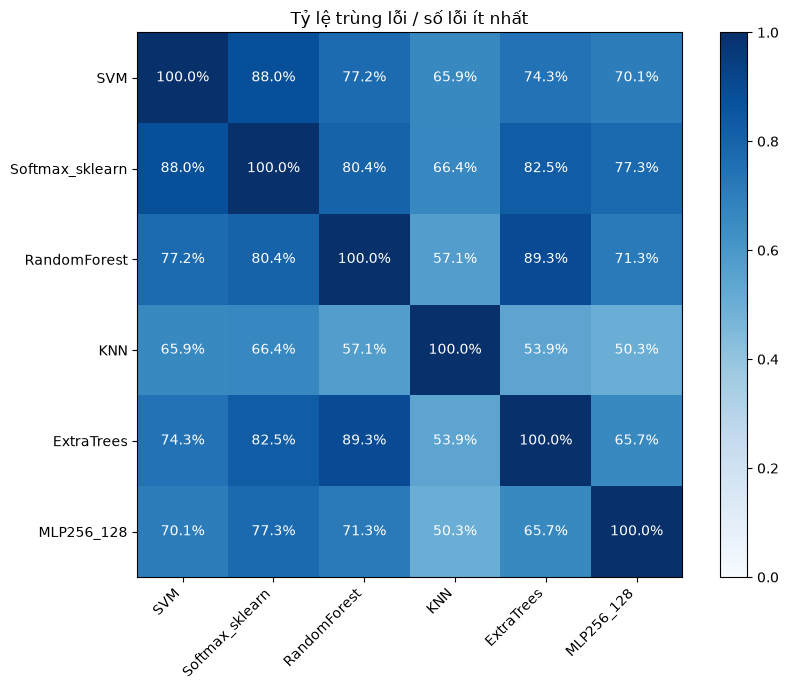

In [5]:
names = list(models)
E = np.array([errors[n] for n in names], dtype=int)
least = np.minimum.outer(E.sum(1), E.sum(1))
heat = np.divide(E @ E.T, least, out=np.full(least.shape, np.nan), where=least > 0)   # NaN nếu mẫu số = 0

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(heat, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(len(names)), names, rotation=45, ha='right')
ax.set_yticks(range(len(names)), names)
for (i, j), v in np.ndenumerate(heat):
    ax.text(j, i, f'{v:.1%}', ha='center', va='center', color='white' if v > 0.5 else 'black')
ax.set_title('Tỷ lệ trùng lỗi / số lỗi ít nhất')
fig.colorbar(im, ax=ax)
fig.tight_layout(); fig.savefig(OUTPUT / 'error_overlap.png', dpi=300); plt.show()

**Heatmap:** tỷ lệ lỗi chung của mỗi cặp so với số lỗi ít nhất trong cặp. Đường chéo bằng 100% nếu có lỗi; mẫu số bằng 0 được ghi NaN.


## 5. Chọn bộ ba

Xếp cặp và bộ ba theo **voting accuracy → F1 macro → double-fault thấp hơn → tên nhóm**. Thời gian chỉ mô tả chi phí. Hiển thị 5 bộ ba đứng đầu và chênh lệch với mô hình đơn tốt nhất; chênh vài ảnh chưa chứng minh lợi thế ổn định.


Bộ ba chọn: ['SVM', 'KNN', 'MLP256_128']


,combo,voting_accuracy,voting_f1,common_errors,mean_double_fault,fit_seconds
0,SVM + KNN + MLP256_128,0.9852,0.98515,81,0.01060,1307.25031
1,SVM + RandomForest + MLP256_128,0.9840,0.98394,97,0.01250,1319.63741
2,SVM + ExtraTrees + MLP256_128,0.9839,0.98383,92,0.01200,1317.45519
3,RandomForest + KNN + MLP256_128,0.9837,0.98362,78,0.01267,353.90247
4,RandomForest + ExtraTrees + MLP256_128,0.9835,0.98345,117,0.01693,364.10735
5,KNN + ExtraTrees + MLP256_128,0.9832,0.98315,75,0.01203,351.72025
6,SVM + RandomForest + ExtraTrees,0.9827,0.98265,121,0.01710,988.41962
7,SVM + KNN + ExtraTrees,0.9815,0.98151,93,0.01283,976.03252
8,SVM + RandomForest + KNN,0.9813,0.98131,94,0.01330,978.21474
9,SVM + Softmax_sklearn + MLP256_128,0.9810,0.98092,103,0.01347,1471.88669


Chênh với mô hình đơn tốt nhất: +0.190 điểm phần trăm


,accuracy,f1_macro,n_errors,fit_seconds
model,,,,
SVM,0.9833,0.98321,167,965.76584
KNN,0.9720,0.97196,280,0.03090
MLP256_128,0.9819,0.98180,181,341.45357


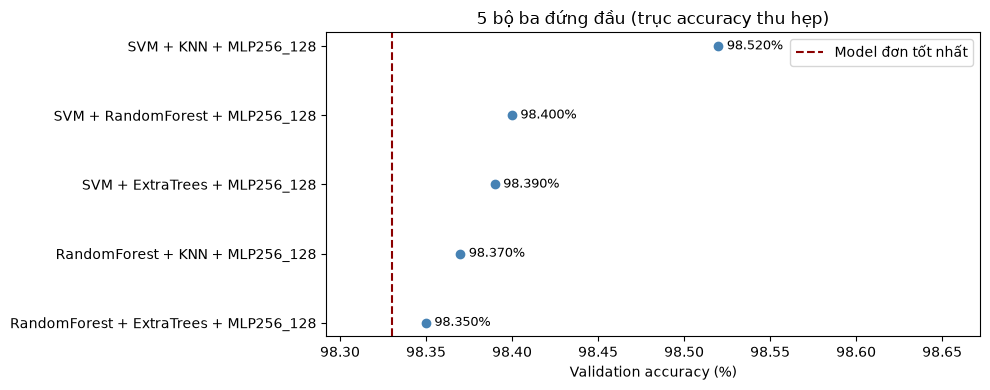

In [6]:
si = singles.set_index('model')
triples['fit_seconds'] = [si.loc[c.split(' + '), 'fit_seconds'].sum() for c in triples.combo]
triples = rank_combos(triples)
selected_row = triples.iloc[0]
selected = selected_row.combo.split(' + ')
print('Bộ ba chọn:', selected)
display(triples[['combo', 'voting_accuracy', 'voting_f1', 'common_errors',
                 'mean_double_fault', 'fit_seconds']].head(10).round(5))
print(f'Chênh với mô hình đơn tốt nhất: {selected_row.gain_over_global_best * 100:+.3f} điểm phần trăm')
display(si.loc[selected, ['accuracy', 'f1_macro', 'n_errors', 'fit_seconds']].round(5))

top = triples.head(5).iloc[::-1]
best_single = singles.accuracy.max() * 100
lo, hi = min(top.voting_accuracy.min() * 100, best_single), max(top.voting_accuracy.max() * 100, best_single)
pad = max((hi - lo) * 0.2, 0.02)
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(top.voting_accuracy * 100, top.combo, color='steelblue')
for combo, acc in zip(top.combo, top.voting_accuracy):
    ax.annotate(f'{acc:.3%}', (acc * 100, combo), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9)
ax.axvline(best_single, color='darkred', linestyle='--', label='Model đơn tốt nhất')
ax.set(xlim=(lo - pad, hi + 4 * pad), xlabel='Validation accuracy (%)', title='5 bộ ba đứng đầu (trục accuracy thu hẹp)')
ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT / 'top_triples.png', dpi=300, bbox_inches='tight'); plt.show()

### 5.1. Đóng góp của từng thành viên

Bỏ lần lượt từng mô hình, so voting của cặp còn lại với bộ ba: số ảnh sửa đúng, làm sai thêm và đóng góp ròng. Tái sử dụng xác suất, không huấn luyện lại.

McNemar so từng bộ ba với hạng 1 chỉ để tham khảo, chưa hiệu chỉnh so sánh nhiều nhóm. p > 0,05 không chứng minh tương đương.


In [7]:
def mcnemar_p(a, b):
    """McNemar exact: chỉ mô tả, không thay thứ hạng hay chứng minh tương đương."""
    n_a, n_b = int((a & ~b).sum()), int((~a & b).sum())
    return 1.0 if n_a + n_b == 0 else binomtest(n_a, n_a + n_b, 0.5).pvalue

full_right = vote_of(selected) == y_val          # selected chính là bộ ba hạng 1
triples['p_vs_top'] = [mcnemar_p(full_right, vote_of(c.split(' + ')) == y_val) for c in triples.combo]
display(triples[['combo', 'voting_accuracy', 'voting_f1', 'p_vs_top']].head(10).round(5))
print('Số nhóm khác có p > 0.05 so với hạng 1:', int((triples.p_vs_top.iloc[1:] > 0.05).sum()))

ablation_rows = []
for removed in selected:
    rest = [n for n in selected if n != removed]
    pair_right = vote_of(rest) == y_val
    corrected, newly_wrong = int((~pair_right & full_right).sum()), int((pair_right & ~full_right).sum())
    ablation_rows.append(dict(removed=removed, pair=' + '.join(rest),
        pair_accuracy=float(pair_right.mean()), triple_accuracy=float(full_right.mean()),
        corrected=corrected, newly_wrong=newly_wrong, net_corrected=corrected - newly_wrong,
        gain_pp=(full_right.mean() - pair_right.mean()) * 100))
ablation = pd.DataFrame(ablation_rows)
display(ablation.round(5))
ablation.to_csv(OUTPUT / 'selected_ablation.csv', index=False)

,combo,voting_accuracy,voting_f1,p_vs_top
0,SVM + KNN + MLP256_128,0.9852,0.98515,1.00000
1,SVM + RandomForest + MLP256_128,0.9840,0.98394,0.11892
2,SVM + ExtraTrees + MLP256_128,0.9839,0.98383,0.07245
3,RandomForest + KNN + MLP256_128,0.9837,0.98362,0.02753
4,RandomForest + ExtraTrees + MLP256_128,0.9835,0.98345,0.04296
5,KNN + ExtraTrees + MLP256_128,0.9832,0.98315,0.00289
6,SVM + RandomForest + ExtraTrees,0.9827,0.98265,0.00463
7,SVM + KNN + ExtraTrees,0.9815,0.98151,0.00006
8,SVM + RandomForest + KNN,0.9813,0.98131,0.00002
9,SVM + Softmax_sklearn + MLP256_128,0.9810,0.98092,0.00000


Số nhóm khác có p > 0.05 so với hạng 1: 2


,removed,pair,pair_accuracy,triple_accuracy,corrected,newly_wrong,net_corrected,gain_pp
0,SVM,KNN + MLP256_128,0.9810,0.9852,56,14,42,0.42
1,KNN,SVM + MLP256_128,0.9838,0.9852,32,18,14,0.14
2,MLP256_128,SVM + KNN,0.9806,0.9852,71,25,46,0.46


### 5.2. So sánh mô hình đơn, cặp và bộ ba

Đối chiếu accuracy, F1 macro, thời gian refit và dự đoán xác suất của ba phương án đứng đầu. `gain_pp` là chênh accuracy theo điểm phần trăm; `extra_correct` là số ảnh đúng tăng ròng so với mô hình đơn. Thời gian đo một lần chỉ mang tính tham khảo.


In [8]:
single = singles.iloc[0]
comparison_rows = [dict(method='Model đơn tốt nhất', models=single.model, accuracy=single.accuracy,
                        f1_macro=single.f1_macro, fit_seconds=single.fit_seconds,
                        predict_seconds=single.proba_seconds)]
for method, row in [('Cặp tốt nhất', pairs.iloc[0]), ('Bộ ba tốt nhất', triples.iloc[0])]:
    members = row.combo.split(' + ')
    _, merge_s = timed(vote_of, members)
    comparison_rows.append(dict(method=method, models=row.combo, accuracy=row.voting_accuracy,
        f1_macro=row.voting_f1, fit_seconds=si.loc[members, 'fit_seconds'].sum(),
        predict_seconds=si.loc[members, 'proba_seconds'].sum() + merge_s))
comparison = pd.DataFrame(comparison_rows)
comparison['gain_pp'] = (comparison.accuracy - single.accuracy) * 100
comparison['extra_correct'] = np.rint((comparison.accuracy - single.accuracy) * len(y_val)).astype(int)
display(comparison.round(5))
gain_pair = comparison.accuracy.iloc[2] - comparison.accuracy.iloc[1]
print(f'Bộ ba so với cặp tốt nhất: {gain_pair*100:+.3f} điểm phần trăm, {gain_pair*len(y_val):+.0f} ảnh đúng (chênh lệch ròng).')
comparison.to_csv(OUTPUT / 'single_pair_triple_comparison.csv', index=False)

,method,models,accuracy,f1_macro,fit_seconds,predict_seconds,gain_pp,extra_correct
0,Model đơn tốt nhất,SVM,0.9833,0.98321,965.76584,53.35396,0.00,0
1,Cặp tốt nhất,SVM + MLP256_128,0.9838,0.98371,1307.21941,53.40408,0.05,5
2,Bộ ba tốt nhất,SVM + KNN + MLP256_128,0.9852,0.98515,1307.25031,61.84985,0.19,19


Bộ ba so với cặp tốt nhất: +0.140 điểm phần trăm, +14 ảnh đúng (chênh lệch ròng).


**Giới hạn:** nhóm tốt nhất theo soft voting trên validation chưa chắc tốt nhất cho stacking. Notebook 06 cần tạo đặc trưng OOF trên train; validation đã dùng chọn nhóm không phải đánh giá độc lập.


## 6. Lưu kết quả

Lưu bảng, hình, xác suất validation và cấu hình tại `results/select_base_models/`.

- `all_estimators.joblib`: 6 estimator chưa fit với cấu hình đã tuning.
- `selected_estimators.joblib`: 3 estimator của nhóm được chọn.
- `candidate_groups.csv`: 3 bộ ba đứng đầu để khảo sát tiếp ở notebook 06.
- `selection.json`: quy tắc chọn, tham số, phiên bản và dấu vân tay train/validation để đối chiếu dữ liệu.


In [9]:
for name, df in dict(singles=singles, pairs=pairs, triples=triples, tuning=tuning_results).items():
    df.to_csv(OUTPUT / f'{name}.csv', index=False)
np.savez_compressed(OUTPUT / 'validation_proba.npz', y_val=y_val, **proba)
(OUTPUT / 'selected_models.txt').write_text('\n'.join(selected), encoding='utf-8')
(OUTPUT / 'best_params.json').write_text(json.dumps(best_params, indent=2), encoding='utf-8')
pd.DataFrame(heat, index=names, columns=names).to_csv(OUTPUT / 'error_overlap.csv')
print('Đã lưu:', OUTPUT)

all_estimators = {n: clone(m) for n, m in models.items()}          # chưa fit, giữ cấu hình đã tuning
dump(all_estimators, OUTPUT / 'all_estimators.joblib')
dump({n: all_estimators[n] for n in selected}, OUTPUT / 'selected_estimators.joblib')
candidate_groups = triples.head(3).copy()
candidate_groups.to_csv(OUTPUT / 'candidate_groups.csv', index=False)

def array_fingerprint(array):
    a = np.ascontiguousarray(array)
    return dict(shape=list(a.shape), dtype=str(a.dtype), sha256=hashlib.sha256(memoryview(a).cast('B')).hexdigest())

fingerprint = {n: array_fingerprint(a) for n, a in
               dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val).items()}
selection_config = dict(
    versions=dict(python=sys.version.split()[0], numpy=np.__version__,
                  sklearn=sklearn.__version__, pandas=pd.__version__),
    seed=SEED, selected_models=selected,
    candidate_groups=[c.split(' + ') for c in candidate_groups.combo],
    selection_rule='equal-weight probability voting; voting_accuracy, voting_f1, '
                   'lower mean_double_fault, combo name; prediction=argmax(predict_proba)',
    voting_accuracy=float(selected_row.voting_accuracy), voting_f1=float(selected_row.voting_f1),
    common_errors=int(selected_row.common_errors), overlap_ratio=float(selected_row.overlap_ratio),
    all_params={n: m.get_params() for n, m in all_estimators.items()},
    data_fingerprint=fingerprint)
(OUTPUT / 'selection.json').write_text(json.dumps(selection_config, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print('Notebook 06: all_estimators.joblib + candidate_groups.csv; các estimator CHƯA fit.')

Đã lưu: d:\Nhận dạng mẫu\mnist\results\select_base_models
Notebook 06: all_estimators.joblib + candidate_groups.csv; các estimator CHƯA fit.
